Iteration 1: Best Distance = 272.86
Iteration 2: Best Distance = 254.47
Iteration 3: Best Distance = 237.00
Iteration 4: Best Distance = 237.00
Iteration 5: Best Distance = 237.00
Iteration 6: Best Distance = 237.00
Iteration 7: Best Distance = 237.00
Iteration 8: Best Distance = 237.00
Iteration 9: Best Distance = 237.00
Iteration 10: Best Distance = 237.00

========== ACO RESULTS ==========
Best Route:
City 2: [30 15]
City 4: [50 10]
City 5: [60 30]
City 6: [70 15]
City 8: [90 10]
City 7: [80 40]
City 9: [50 60]
City 3: [40 40]
City 1: [20 30]
City 0: [10 10]
City 2: [30 15]

Minimum Total Distance: 237.0
Total Iterations: 10


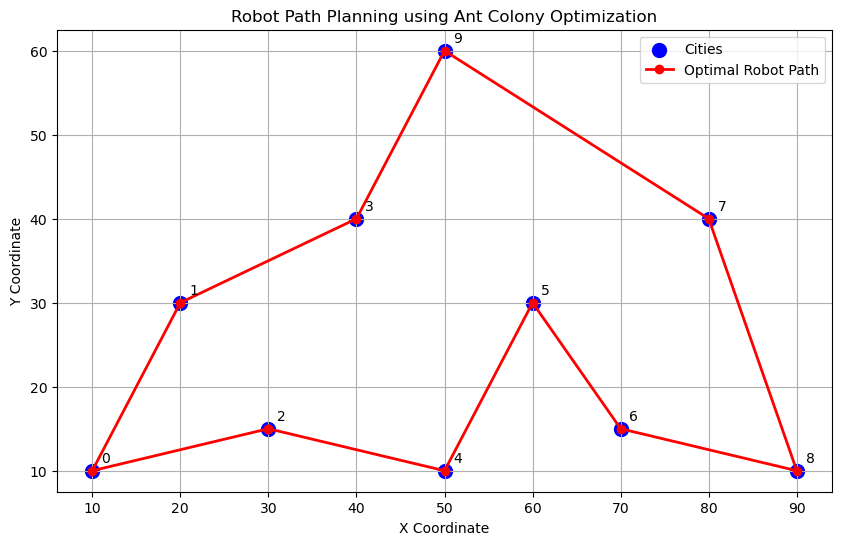

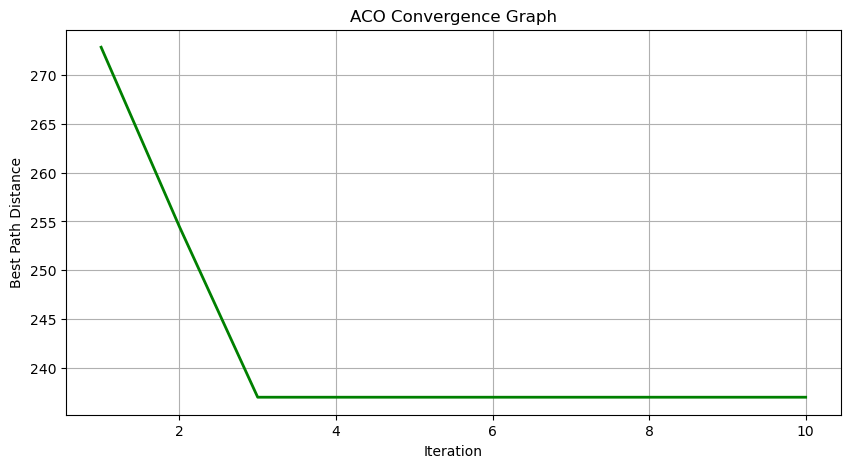

In [2]:

import numpy as np
import random
import matplotlib.pyplot as plt
random.seed(42)
np.random.seed(42)
cities = np.array([
    [10, 10],
    [20, 30],
    [30, 15],
    [40, 40],
    [50, 10],
    [60, 30],
    [70, 15],
    [80, 40],
    [90, 10],
    [50, 60]
])
n = len(cities)
distance = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        if i != j:
            distance[i][j] = np.sqrt(
                (cities[i][0] - cities[j][0])**2 +
                (cities[i][1] - cities[j][1])**2
            )
heuristic = np.zeros((n, n))
heuristic[distance > 0] = 1 / distance[distance > 0]
N = 20                 # Number of ants
alpha = 1.0            # Pheromone importance
beta = 2.0             # Heuristic importance
rho = 0.5              # Evaporation rate
Q = 100                # Pheromone deposit constant
tau0 = 0.1             # Initial pheromone
max_iterations = 10
pheromone = np.ones((n, n)) * tau0
best_route = None
best_distance = float('inf')
best_distances = []
for iteration in range(max_iterations):
    all_routes = []
    all_distances = []
    for ant in range(N):
        start = random.randint(0, n - 1)
        route = [start]
        visited = set(route)
        while len(visited) < n:
            current = route[-1]
            allowed = [
                city for city in range(n)
                if city not in visited
            ]
            probabilities = []
            for city in allowed:
                numerator = (
                    pheromone[current][city] ** alpha *
                    heuristic[current][city] ** beta
                )
                probabilities.append(numerator)
            probabilities = np.array(probabilities)
            probabilities = probabilities / np.sum(probabilities)
            next_city = random.choices(
                allowed,
                weights=probabilities,
                k=1
            )[0]
            route.append(next_city)
            visited.add(next_city)
        route.append(start)
        total_distance = 0
        for i in range(len(route) - 1):
            total_distance += distance[
                route[i]
            ][
                route[i + 1]
            ]
        all_routes.append(route)
        all_distances.append(total_distance)
        if total_distance < best_distance:
            best_distance = total_distance
            best_route = route.copy()
    pheromone *= (1 - rho)
    for ant in range(N):
        route = all_routes[ant]
        route_distance = all_distances[ant]
        deposit = Q / route_distance
        for i in range(len(route) - 1):
            city1 = route[i]
            city2 = route[i + 1]
            pheromone[city1][city2] += deposit
            pheromone[city2][city1] += deposit

    best_distances.append(best_distance)

    print(
        f"Iteration {iteration + 1}: "
        f"Best Distance = {best_distance:.2f}"
    )
print("\n========== ACO RESULTS ==========")
print("Best Route:")
for city in best_route:
    print(
        f"City {city}: "
        f"{cities[city]}"
    )
print("\nMinimum Total Distance:",
      round(best_distance, 2))
print("Total Iterations:", max_iterations)
plt.figure(figsize=(10, 6))
plt.scatter(
    cities[:, 0],
    cities[:, 1],
    color='blue',
    s=100,
    label='Cities'
)
for i, (x, y) in enumerate(cities):
    plt.text(x + 1, y + 1, f'{i}')
route_coordinates = cities[best_route]
plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    'r-o',
    linewidth=2,
    markersize=6,
    label='Optimal Robot Path'
)
plt.title('Robot Path Planning using Ant Colony Optimization')
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.legend()
plt.grid(True)
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, max_iterations + 1),
    best_distances,
    color='green',
    linewidth=2
)
plt.title('ACO Convergence Graph')
plt.xlabel('Iteration')
plt.ylabel('Best Path Distance')
plt.grid(True)
plt.show()
